# Santiago Rodriguez y Samuel Serrano Poveda

# ¿Se parecen dos frases? El coseno lo decide

**Álgebra Lineal** · Departamento de Ciencias Básicas y Matemáticas · Pontificia Universidad
Javeriana Cali

---

Un buscador tiene que decidir si *«los estudiantes estudian en la biblioteca»* se parece más
a *«los estudiantes resuelven ejercicios»* o a *«la gente baila salsa en el parque»*.

Para decidirlo hay que convertir cada frase en un **vector** y medir el **ángulo** entre
ellos. Eso es todo lo que vamos a hacer hoy.

---

| Parte | Qué hace usted | Puntos | Tiempo |
|---|---|---|---|
| **1** | **Leer y ejecutar.** El código viene hecho. Solo hay que entender de dónde salen los vectores. | — | 15 min |
| **2** | **Comparar dos frases**, paso a paso: sumar, promediar, coseno, interpretar. | **60** | 30 min |
| **3** | Resolver **una ecuación que ya viene planteada** y contestar: ¿está la frase en el generado? | **40** | 25 min |

> **No va a necesitar ningún ciclo.** Cada paso que usted escribe es **una sola línea** de
> NumPy. Si siente que necesita un `for`, le falta una operación vectorial.

> **Autocontenido.** Todo está en este cuaderno: no se descarga ni se instala nada.


—
# Parte 1 — De dónde salen los vectores

*No se califica. Lea, ejecute y entienda: en las Partes 2 y 3 va a usar estos vectores.*

## 1.1 · El objetivo: volver vector una frase

Un buscador recibe *«los estudiantes resuelven ejercicios»* y tiene que decidir cuál de
las frases que guarda se le parece más. Un detector de copia tiene que decidir si dos
párrafos dicen lo mismo con otras palabras. Un profesor con $300$ respuestas escritas tiene
que agruparlas por lo que dicen.

Las tres son **la misma pregunta**: ¿qué tan parecidas son dos frases? Y usted ya sabe
responderla **cuando las cosas son vectores**:

$$\cos\theta=\frac{\vec u\cdot\vec v}{\lVert \vec u\rVert \;\lVert \vec v\rVert }$$

cerca de $1$ apuntan en la misma dirección, cerca de $0$ son perpendiculares. El coseno no
sabe de texto: sabe de vectores. Así que todo el trabajo está en **convertir la frase en un
vector** de modo que el ángulo signifique algo.

El plan es de tres pasos, y la Parte 1 es el primero:

| | Paso | Dónde |
|---|---|---|
| 1 | cada **palabra** se vuelve un vector | Parte 1 (ya hecho) |
| 2 | la **frase** es el promedio de los vectores de sus palabras | Parte 2 |
| 3 | el **coseno** entre esos dos vectores responde la pregunta | Parte 2 |

Vamos a seguir una sola frase de ejemplo durante toda esta parte:

> ### «En el río Cali se baila salsa»

## 1.2 · Primero: botar las palabras vacías

En esa frase hay siete palabras, pero tres no aportan nada:

$$\underbrace{\texttt{En}\quad\texttt{el}}_{\text{vacías}}\quad
  \texttt{río}\quad\texttt{Cali}\quad
  \underbrace{\texttt{se}}_{\text{vacía}}\quad
  \texttt{baila}\quad\texttt{salsa}$$

Se llaman **palabras vacías** (*stop words*) y se quitan por tres razones:

1. **No dicen de qué habla el texto.** `en` y `el` aparecen igual en un texto de cocina,
   en uno de física y en este de salsa. No distinguen nada.
2. **Son las más frecuentes y aparecen cerca de todo.** Si las dejamos, *todas* las
   palabras del corpus terminarían compartiendo vecinos con `el` y con `de`, y todos los
   parecidos subirían por igual. El efecto es que **se borra la información** que
   queríamos medir.
3. **Ocupan la ventana.** Vamos a mirar solo unas pocas palabras a cada lado. Si contamos
   `en`, `el` y `se`, el relleno empuja afuera a `salsa` —que es justo la que importa—.

Nos queda una secuencia de **cuatro palabras de contenido**:

$$\underset{0}{\texttt{río}}\quad \underset{1}{\texttt{cali}}\quad
  \underset{2}{\texttt{baila}}\quad \underset{3}{\texttt{salsa}}$$

> **El precio de quitarlas:** la distancia se mide ahora **entre palabras de contenido**, no
> en el texto original. En la frase `baila` y `salsa` estaban pegadas y siguen a distancia
> $1$, pero `río` y `baila` pasaron de estar a $3$ palabras a estar a $2$. Es una decisión
> nuestra, y es la que toman casi todos los sistemas reales.

## 1.3 · El *one-hot* y por qué no sirve

La forma más simple de volver vector una palabra es **one-hot**: se ordena el vocabulario y
cada palabra recibe un $1$ en su propia posición y $0$ en todas las demás. Con el
vocabulario de nuestra frase, en orden alfabético
$(\texttt{baila},\ \texttt{cali},\ \texttt{río},\ \texttt{salsa})$:

$$\texttt{baila}\mapsto(1,0,0,0),\quad
  \texttt{cali}\mapsto(0,1,0,0),\quad
  \texttt{río}\mapsto(0,0,1,0),\quad
  \texttt{salsa}\mapsto(0,0,0,1).$$

Mida ahora el coseno de cualquier par: **siempre da $0$**, porque los unos nunca caen en la
misma posición.

$$\cos(\texttt{río},\texttt{cali})=0,\qquad
  \cos(\texttt{río},\texttt{salsa})=0,\qquad
  \cos(\texttt{baila},\texttt{salsa})=0 .$$

**Todas las palabras salen ortogonales entre sí**, a $90^\circ$ unas de otras. El one-hot
sabe *distinguir* palabras, pero no sabe que `río` y `cali` acaban de aparecer pegadas, ni
que en Cali `baila` y `salsa` van siempre juntas. Como todos los ángulos son iguales, el
coseno no puede ordenar nada: es inservible para nuestra pregunta.

## 1.4 · El cambio: llenar los ceros con la cercanía

Cambiamos **una sola cosa**. En lugar de poner $0$ en las demás posiciones, ponemos
**qué tan cerca** aparece cada palabra:

> El vector de la palabra $w$ tiene
> - un $\mathbf{1}$ en su propia posición (eso se conserva del one-hot), y
> - en la posición de otra palabra $c$, la suma de $\dfrac{1}{d}$ por **cada vez** que $c$
>   aparece a distancia $d$ de $w$, dentro de una **ventana** de unas pocas palabras a cada
>   lado.
>
> Al final el vector se **normaliza** (se divide por su norma).

El peso $1/d$ dice exactamente lo que queremos: un vecino pegado ($d=1$) aporta $1$; uno a
cinco palabras aporta apenas $1/5$; más lejos de la ventana, nada.

### En nuestra frase, con ventana $\pm2$

$$\underset{0}{\texttt{río}}\quad \underset{1}{\texttt{cali}}\quad
  \underset{2}{\texttt{baila}}\quad \underset{3}{\texttt{salsa}}$$

Las seis cuentas, una por una:

| par | distancia | aporta |
|---|---|---|
| `río` – `cali` | $1$ | $1$ |
| `río` – `baila` | $2$ | $\tfrac12$ |
| `río` – `salsa` | $3$ | **fuera de la ventana**: $0$ |
| `cali` – `baila` | $1$ | $1$ |
| `cali` – `salsa` | $2$ | $\tfrac12$ |
| `baila` – `salsa` | $1$ | $1$ |

$$M=\begin{pmatrix}
1 & 1 & \tfrac12 & 1\\
1 & 1 & 1 & \tfrac12\\
\tfrac12 & 1 & 1 & 0\\
1 & \tfrac12 & 0 & 1
\end{pmatrix}
\qquad\text{\small filas y columnas en el orden }
(\texttt{baila},\texttt{cali},\texttt{río},\texttt{salsa})$$

### Qué se ganó

Normalizando las filas y midiendo el coseno:

$$\cos(\texttt{río},\texttt{cali})=\frac{10\sqrt{13}}{39}\approx 0{,}9245,
  \qquad
  \cos(\texttt{río},\texttt{salsa})=\frac49\approx 0{,}4444 .$$

Con one-hot los dos valían $0$. Ahora:

- **`río` y `cali` casi coinciden** ($0{,}92$): aparecieron pegadas.
- **`río` y `salsa` dan $0{,}44$**, y esto es lo interesante: esas dos palabras **nunca
  caen en la ventana de la otra** —están a distancia $3$—. Su coseno no es cero porque
  **comparten vecinos**: las dos tienen a `cali` y a `baila` cerca. El modelo dedujo un
  parecido que no estaba escrito en ninguna parte.

> Esa es toda la idea del taller, y la frase para llevarse:
> **una palabra significa con quién aparece.** Dos palabras se parecen cuando aparecen
> rodeadas de las mismas palabras, aunque nunca se encuentren.

En el párrafo real usaremos **ventana $\pm5$** (cinco a la izquierda y cinco a la derecha)
en lugar de $\pm2$.

## 1.5 · El código, completo

Lo que acaba de hacer a mano con cuatro palabras, ahora con un párrafo entero. Ejecute las
cuatro celdas siguientes. **No hay nada que completar**: léalas con el comentario de al
lado y quédese con la idea de cada paso.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- el párrafo: todo el taller sale de aquí ----------
TEXTO = """La universidad Javeriana queda en el sur de Cali. Cada mañana los
estudiantes cruzan el campus y caminan hacia la biblioteca. En la biblioteca los
estudiantes estudian álgebra lineal y resuelven ejercicios con vectores y
matrices. Por la tarde la ciudad cambia de ritmo. En el parque junto al río la
gente baila salsa, y la salsa suena en las esquinas del barrio."""

VACIAS = np.array(['la', 'el', 'los', 'las', 'de', 'del', 'en', 'y', 'a', 'al',
                   'un', 'una', 'con', 'por', 'su', 'sus', 'que', 'se', 'es', 'lo'])
SIGNOS = str.maketrans('', '', '.,;:!¿?¡()«»"')
VENTANA = 5

print(TEXTO)

La universidad Javeriana queda en el sur de Cali. Cada mañana los
estudiantes cruzan el campus y caminan hacia la biblioteca. En la biblioteca los
estudiantes estudian álgebra lineal y resuelven ejercicios con vectores y
matrices. Por la tarde la ciudad cambia de ritmo. En el parque junto al río la
gente baila salsa, y la salsa suena en las esquinas del barrio.


In [2]:
# ---------- PASO A: del texto a una lista de palabras de contenido ----------
tok = np.array(TEXTO.lower().translate(SIGNOS).split())   # minúsculas, sin signos
tok = tok[~np.isin(tok, VACIAS)]                          # fuera las palabras vacías

# vocab = palabras distintas (alfabético) · idx = a qué palabra corresponde cada token
vocab, primera, idx = np.unique(tok, return_index=True, return_inverse=True)
T, V = len(tok), len(vocab)

print(f"T = {T} palabras de contenido · V = {V} palabras distintas\n")
print("la secuencia quedó así:\n ", " ".join(tok))

T = 36 palabras de contenido · V = 33 palabras distintas

la secuencia quedó así:
  universidad javeriana queda sur cali cada mañana estudiantes cruzan campus caminan hacia biblioteca biblioteca estudiantes estudian álgebra lineal resuelven ejercicios vectores matrices tarde ciudad cambia ritmo parque junto río gente baila salsa salsa suena esquinas barrio


In [48]:
# ---------- PASO B: la matriz de proximidad entre palabras ----------
# O marca, para cada posición del texto, qué palabra del vocabulario está ahí
O = np.eye(V)[idx]                                   # T x V

# Dist[p, q] = a cuántas palabras de distancia están las posiciones p y q
pos = np.arange(T)
Dist = np.abs(pos[:, None] - pos[None, :])           # T x T

# Wm[p, q] = 1/distancia si están dentro de la ventana; 0 si no
Wm = np.where((Dist >= 1) & (Dist <= VENTANA), 1.0 / np.maximum(Dist, 1), 0.0)

# el producto junta las dos cosas: para cada par de PALABRAS, suma los 1/d
M = O.T @ Wm @ O                                     # V x V
np.fill_diagonal(M, 1.0)                             # el 1 que venía del one-hot

print("O:", O.shape, "· Dist:", Dist.shape, "· Wm:", Wm.shape, "· M:", M.shape)

O: (36, 33) · Dist: (36, 36) · Wm: (36, 36) · M: (33, 33)


In [4]:
# ---------- PASO C: normalizar ----------
# cada fila se divide por su norma: así una palabra frecuente no sale
# «parecida a todo» solo por ser frecuente
Mn = M / np.linalg.norm(M, axis=1, keepdims=True)

print("¿todas las filas quedaron de norma 1?", np.allclose(np.linalg.norm(Mn, axis=1), 1))
print()
print("ejemplo — el vector de 'biblioteca' (solo sus entradas no nulas):")
fila = Mn[np.where(vocab == 'biblioteca')[0][0]]
print(np.column_stack([vocab[fila > 0], np.round(fila[fila > 0], 3)]))

¿todas las filas quedaron de norma 1? True

ejemplo — el vector de 'biblioteca' (solo sus entradas no nulas):
[['biblioteca' '0.34']
 ['caminan' '0.283']
 ['campus' '0.198']
 ['cruzan' '0.153']
 ['estudian' '0.283']
 ['estudiantes' '0.578']
 ['hacia' '0.51']
 ['lineal' '0.153']
 ['resuelven' '0.068']
 ['álgebra' '0.198']]


### Qué acaba de pasar

La fila de `biblioteca` dice: *«aparezco cerca de `estudiantes`, `estudian`, `campus`,
`caminan`…»*, y cada número mide **qué tan cerca**. Ese es el vector de la palabra.

Dos palabras se parecerán cuando sus filas apunten en la misma dirección, es decir cuando
**aparezcan rodeadas de las mismas palabras**. Esa es toda la idea.

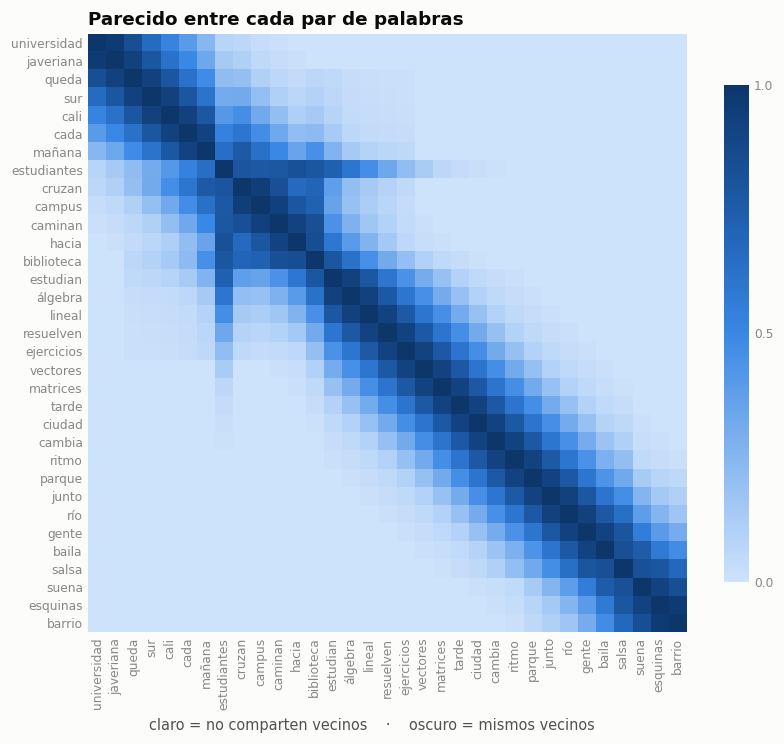

In [6]:
# ---------- el mapa de parecidos entre todas las palabras ----------
COS = Mn @ Mn.T                      # todos los cosenos de una vez
orden = np.argsort(primera)          # las palabras en el orden en que aparecen

TINTA, SUAVE, TENUE, FONDO = '#0b0b0b', '#52514e', '#898781', '#fcfcfb'
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list(
    'azul', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({'figure.facecolor': FONDO, 'axes.facecolor': FONDO,
                     'axes.titlecolor': TINTA, 'axes.titlesize': 12,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'xtick.color': TENUE, 'ytick.color': TENUE,
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'figure.dpi': 110})

fig, ax = plt.subplots(figsize=(7.8, 7.0))
im = ax.imshow(COS[np.ix_(orden, orden)], cmap=CMAP, vmin=0, vmax=1)
ax.set_xticks(np.arange(V), vocab[orden], rotation=90)
ax.set_yticks(np.arange(V), vocab[orden])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title('Parecido entre cada par de palabras')
cb = fig.colorbar(im, ax=ax, shrink=0.72, ticks=[0, 0.5, 1])
cb.outline.set_visible(False); cb.ax.tick_params(length=0, colors=TENUE)
fig.text(0.44, 0.015, 'claro = no comparten vecinos    ·    oscuro = mismos vecinos',
         ha='center', fontsize=9.5, color=SUAVE)
plt.tight_layout(); plt.show()

### Lo que muestra el mapa

- Hay una **banda oscura sobre la diagonal**: las palabras vecinas en el texto comparten
  casi toda su ventana.
- Las **dos esquinas están en blanco**. El párrafo tiene dos mitades —la universidad por
  la mañana, la ciudad por la tarde— separadas por más de cinco palabras de contenido.
  Ninguna palabra de una mitad cae jamás en la ventana de la otra, así que su producto
  punto es **exactamente cero**: son ortogonales.

Esa es la señal que vamos a aprovechar en la Parte 2.

—
# Parte 2 — ¿Se parecen dos frases? · 60 puntos · ≈30 min

**Esta parte sí se califica.** Vamos paso a paso.

Una frase no es una palabra: tiene varias. La receta es la más simple posible:

> **Sume** los vectores de sus palabras y **divida entre el número de palabras**. Ese
> promedio es el vector de la frase.

Trabajaremos con estas tres:

| | Frase | Palabras de contenido |
|---|---|---|
| **A** | los estudiantes estudian en la biblioteca | `estudiantes` `estudian` `biblioteca` |
| **B** | los estudiantes resuelven ejercicios | `estudiantes` `resuelven` `ejercicios` |
| **C** | la gente baila salsa en el parque | `gente` `baila` `salsa` `parque` |

## Paso 1 · Buscar el vector de una palabra · 8 puntos

`vocab` está ordenado alfabéticamente. Para encontrar la fila de una palabra:

```python
np.where(vocab == 'biblioteca')[0][0]      # la posición de esa palabra
Mn[posición]                                # su vector
```

**(a)** Guarde en `v_est`, `v_estudian` y `v_bib` los vectores de `estudiantes`,
`estudian` y `biblioteca`.

In [36]:
i_est = np.where(vocab == 'estudiantes')[0][0]
# PASO 1 parte (a): tenenmos que buscar en que posición del vocabulario esta cada palabra
# y con esa posición saco su fila de Mn, que es el vector de la palabra.
i_estudian = np.where(vocab == 'estudian')[0][0]
i_bib = np.where(vocab == 'biblioteca')[0][0]

v_est = Mn[i_est]
v_estudian = Mn[i_estudian]
v_bib = Mn[i_bib]

print("cada vector tiene", v_est.shape[0], "componentes (una por palabra del vocabulario)")
print("y norma 1:", np.round([np.linalg.norm(v_est),
                              np.linalg.norm(v_estudian),
                              np.linalg.norm(v_bib)], 6))

cada vector tiene 33 componentes (una por palabra del vocabulario)
y norma 1: [1. 1. 1.]


## Paso 2 · Sumar · 8 puntos

**(b)** Sume los tres vectores de la frase **A** y guarde el resultado en `suma_A`.

$$\text{suma}_A=\vec v_{\texttt{estudiantes}}+\vec v_{\texttt{estudian}}+\vec v_{\texttt{biblioteca}}$$

In [37]:
# PASO 2 parte (b): vamos a sumar componente a componente, los vectores de las tres palabras de la frase A.
suma_A = v_est + v_estudian + v_bib

print(" la norma de la suma:", round(float(np.linalg.norm(suma_A)), 4))

 la norma de la suma: 2.7564


## Paso 3 · Promediar · 8 puntos

**(c)** Divida entre $3$ —el número de palabras— y guarde el promedio en `A`.

$$\vec f_A=\frac{\vec v_{\texttt{estudiantes}}+\vec v_{\texttt{estudian}}+\vec v_{\texttt{biblioteca}}}{3}$$

*¿Por qué promediar y no solo sumar?* Para que una frase larga no salga automáticamente
«más grande» que una corta. El promedio deja el vector **a la escala de una palabra**.

In [38]:
# PASO 3 parte (c): vamos a dividir la suma entre 3 (número de palabras) para obtener el promedio = vector de la frase A.
A = suma_A / 3

print("norma del promedio:", round(float(np.linalg.norm(A)), 4))
print("norma de la suma   :", round(float(np.linalg.norm(suma_A)), 4))
print("la suma es", round(float(np.linalg.norm(suma_A)/np.linalg.norm(A)), 2), "veces más larga")

norma del promedio: 0.9188
norma de la suma   : 2.7564
la suma es 3.0 veces más larga


## Paso 4 · Hacer lo mismo con las otras dos frases · 10 puntos

**(d)** Arme `B` (promedio de `estudiantes`, `resuelven`, `ejercicios`) y `C` (promedio de
`gente`, `baila`, `salsa`, `parque`). **Ojo: `C` tiene cuatro palabras**, así que se divide
entre $4$.

In [39]:
# PASO 4 parte(d): vamos a hacer lo mismo con B (3 palabras -> /3) y con C (4 palabras -> /4).
B = (Mn[np.where(vocab == 'estudiantes')[0][0]] + Mn[np.where(vocab == 'resuelven')[0][0]] + Mn[np.where(vocab == 'ejercicios')[0][0]]) / 3
C = (Mn[np.where(vocab == 'gente')[0][0]] + Mn[np.where(vocab == 'baila')[0][0]] + Mn[np.where(vocab == 'salsa')[0][0]] + Mn[np.where(vocab == 'parque')[0][0]]) / 4

print("norma de A:", round(float(np.linalg.norm(A)), 4))
print("norma de B:", round(float(np.linalg.norm(B)), 4))
print("norma de C:", round(float(np.linalg.norm(C)), 4))

norma de A: 0.9188
norma de B: 0.8102
norma de C: 0.8582


## Paso 5 · El coseno · 12 puntos

Ya es la fórmula de siempre:

$$\cos\theta=\frac{\vec u\cdot\vec v}{\lVert \vec u\rVert \;\lVert \vec v\rVert }$$

En NumPy: `u @ v / (np.linalg.norm(u) * np.linalg.norm(v))`.

**(e)** Calcule los tres cosenos: `cos_AB`, `cos_AC` y `cos_BC`, y sus tres ángulos en
grados. *Para el ángulo: `np.degrees(np.arccos(np.clip(c, -1, 1)))`.*

In [40]:
# PASO 5 parte (e): el coseno = producto punto / (norma del uno * norma del otro). Despues el ángulo con arccos pasado a grados.
# np.clip evita errores numéricos (que el coseno se pase de 1 por una milésima).
cos_AB = A @ B / (np.linalg.norm(A) * np.linalg.norm(B))
cos_AC = A @ C / (np.linalg.norm(A) * np.linalg.norm(C))
cos_BC = B @ C / (np.linalg.norm(B) * np.linalg.norm(C))

ang_AB = np.degrees(np.arccos(np.clip(cos_AB, -1, 1)))
ang_AC = np.degrees(np.arccos(np.clip(cos_AC, -1, 1)))
ang_BC = np.degrees(np.arccos(np.clip(cos_BC, -1, 1)))

print(f"A vs B   cos = {cos_AB:.4f}   ángulo = {ang_AB:6.2f}°")
print(f"A vs C   cos = {cos_AC:.4f}   ángulo = {ang_AC:6.2f}°")
print(f"B vs C   cos = {cos_BC:.4f}   ángulo = {ang_BC:6.2f}°")

A vs B   cos = 0.6872   ángulo =  46.59°
A vs C   cos = 0.0000   ángulo =  90.00°
B vs C   cos = 0.0183   ángulo =  88.95°


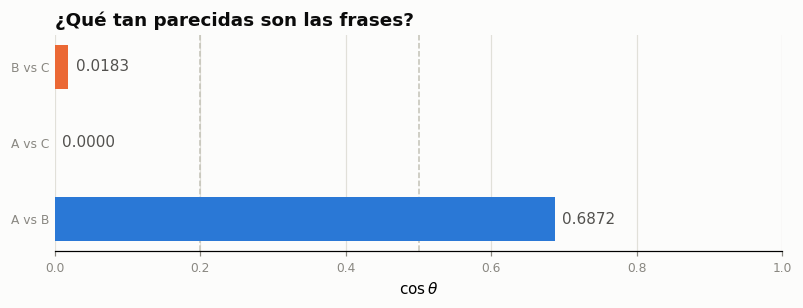

In [41]:
# --- la figura (ya viene hecha) ---
AZUL, NARANJA, AGUA = '#2a78d6', '#eb6834', '#1baf7a'
pares = np.array(['A vs B', 'A vs C', 'B vs C'])
vals = np.array([cos_AB, cos_AC, cos_BC])
colores = np.where(vals >= 0.5, AZUL, np.where(vals >= 0.2, AGUA, NARANJA))

fig, ax = plt.subplots(figsize=(7.4, 2.9))
barras = ax.barh(np.arange(3), vals, height=0.58, color=colores, zorder=3)
ax.bar_label(barras, fmt='%.4f', padding=5, fontsize=10, color='#52514e')
ax.set_yticks(np.arange(3), pares)
ax.set_xlim(0, 1.0)
ax.axvline(0.5, color='#c3c2b7', linewidth=1, linestyle='--', zorder=1)
ax.axvline(0.2, color='#c3c2b7', linewidth=1, linestyle='--', zorder=1)
ax.set_xlabel(r'$\cos\theta$')
ax.set_title('¿Qué tan parecidas son las frases?')
ax.grid(axis='x', zorder=0, color='#e1e0d9')
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout(); plt.show()

## Paso 6 · Interpretar · 14 puntos

Esta tabla es la que hay que saber leer:

| $\cos\theta$ | Ángulo | Qué significa |
|---|---|---|
| cerca de $1$ | cerca de $0^\circ$ | las frases usan palabras que aparecen **en los mismos contextos**: hablan de lo mismo |
| alrededor de $0{,}5$ | alrededor de $60^\circ$ | comparten **parte** del vocabulario o del contexto |
| cerca de $0$ | cerca de $90^\circ$ | **no comparten nada**: son temas ajenos |

> En este modelo el coseno **nunca es negativo**, porque todas las entradas de $M$ son
> $\ge0$. Los ángulos viven entre $0^\circ$ y $90^\circ$, y $90^\circ$ es el desacuerdo
> máximo posible.

**(f)** Conteste, en dos o tres líneas cada una:

1. ¿Cuál par de frases es el más parecido? Diga el coseno y el ángulo, y explique **por
   qué** mirando las palabras de las dos frases.
2. El par **A vs C** da un coseno de **exactamente** cero. ¿Qué significa eso, en términos
   del párrafo? ¿Por qué es cero exacto y no «casi cero»?
3. Si el buscador recibe la consulta *«los estudiantes resuelven ejercicios»*, ¿qué frase
   le devolvería primero? ¿Por qué?

> *Su respuesta:*
> 1. El par más parecido es A vs B: coseno  ≈ 0,6872 y ángulo ≈ 46,59°. Las dos tienen la palabra "estudiantes", y las demás ("estudian", "biblioteca", "resuelven", "ejercicios") salen en la misma parte del párrafo, la de la universidad, entonces comparten vecinos.
> 2. A vs C da 0 exacto (90°). Quiere decir que no tienen nada en común: A es de la universidad en la mañana y C es de la salsa en el parque en la tarde. Es exactamente cero porque las dos mitades del párrafo quedan a más de 5 palabras una de la otra (la ventana), así que nunca se encuentran y todos los términos del producto punto son 0.
> 3. Devolvería primero la frase A, porque la consulta es la frase B y cos(B, A) ≈ 0,687 frente a cos(B, C) ≈ 0,018. A esta a 46,6° de la consulta y C a casi 90°.

In [42]:
# --- una observación que vale la pena mirar ---
# ¿qué pasa si NO promediamos y usamos la suma?
cos_suma = suma_A @ B / (np.linalg.norm(suma_A) * np.linalg.norm(B))

print(f"con el promedio A : cos = {cos_AB:.10f}")
print(f"con la suma  suma_A: cos = {cos_suma:.10f}")
print()
print("¿son iguales?", np.isclose(cos_AB, cos_suma))

con el promedio A : cos = 0.6871967114
con la suma  suma_A: cos = 0.6871967114

¿son iguales? True


**(g)** La celda anterior muestra que **la suma y el promedio dan exactamente el mismo
coseno**, aunque sus normas sean distintas (una es $3$ veces la otra). Explique por qué.

*Pista: escriba $\vec f_A=\tfrac13\,\text{suma}_A$ y reemplace en la fórmula del coseno.*

> *Su respuesta:*
como $\vec f_A=\tfrac13\,\text{suma}_A$, al reemplazar en la fórmula:
>
> cos(f_A, B) = (f_A · B) / (‖f_A‖ ‖B‖) = ((1/3) suma_A · B) / ((1/3)‖suma_A‖ ‖B‖) = (suma_A · B) / (‖suma_A‖ ‖B‖)
>
> El factor 1/3 sale del producto punto
 y también de la norma (‖k·v‖ = |k|·‖v‖ con k > 0), y se cancela arriba y abajo. El coseno mide solo la dirección del vector, no su longitud, y dividir entre 3 cambia la longitud pero no la dirección.

—
# Parte 3 — ¿Está la frase en el generado? · 40 puntos · ≈25 min

Hasta aquí midió **ángulos**. Ahora una pregunta distinta, de las de sistemas de
ecuaciones.

La frase **A** se armó con tres palabras. Pregunta: **¿se puede escribir el vector de una
frase como combinación lineal de los vectores de esas tres palabras?** Es decir, ¿existen
números $c_1,c_2,c_3$ tales que

$$\boxed{\;c_1\,\vec v_{\texttt{estudiantes}}
        +c_2\,\vec v_{\texttt{estudian}}
        +c_3\,\vec v_{\texttt{biblioteca}}
        =\vec f\;}$$

Esa es exactamente la ecuación $P\vec c=\vec f$, donde la matriz $P$ tiene esas tres
palabras como **columnas**. (La llamamos $P$, de *palabras*: la letra $A$ ya está ocupada
por la frase **A**.) Y responderla es preguntar si $\vec f$ está en
$\operatorname{gen}\{\vec v_{\texttt{estudiantes}},\vec v_{\texttt{estudian}},\vec v_{\texttt{biblioteca}}\}$.

La matriz ya viene armada:

In [43]:
# ---------- la matriz del sistema (ya viene hecha) ----------
P = np.column_stack([v_est, v_estudian, v_bib])     # 33 filas, 3 columnas

print("P tiene", P.shape[0], "filas y", P.shape[1], "columnas")
print("cada columna es el vector de una palabra:")
print("   columna 1 -> estudiantes")
print("   columna 2 -> estudian")
print("   columna 3 -> biblioteca")

P tiene 33 filas y 3 columnas
cada columna es el vector de una palabra:
   columna 1 -> estudiantes
   columna 2 -> estudian
   columna 3 -> biblioteca


## Caso 1 · $\vec f=\vec f_A$, el promedio de esas mismas tres palabras · 20 puntos

**(a)** ¿Tiene solución la ecuación? Para decidirlo use el criterio de siempre: **comparar
el número de pivotes** de $P$ con el de $[\,P\mid\vec f\,]$. `numpy` los cuenta con
`np.linalg.matrix_rank`.

**(b)** Resuelva y **verifique**.

In [45]:
# PARTE 3, CASO 1 (a): cuento los pivotes de P y de la matriz aumentada [P | f_A].
# Si son iguales, el sistema P c = f_A tiene solución (f_A está en el generado).
P = np.column_stack([v_est, v_estudian, v_bib]) # Asegurar que P está definido
piv_P = np.linalg.matrix_rank(P)
piv_Pf = np.linalg.matrix_rank(np.column_stack([P, A])) # COMPLETAR: pivotes de la matriz aumentada
# pista: np.column_stack([P, A])

print("pivotes de P        :", piv_P)
print("pivotes de [P | f_A]:", piv_Pf)
print("¿son iguales?       :", piv_P == piv_Pf)

# --- (b) resolver y verificar ---
c = np.linalg.lstsq(P, A, rcond=None)[0]

print()
print("coeficientes c =", np.round(c, 6))
print("¿P @ c = f_A?", np.allclose(P @ c, A))

pivotes de P        : 3
pivotes de [P | f_A]: 3
¿son iguales?       : True

coeficientes c = [0.333333 0.333333 0.333333]
¿P @ c = f_A? True


**(c)** Los tres coeficientes dieron el mismo número. ¿Cuál es, y **por qué era de
esperarse**? Mire cómo definió $\vec f_A$ en el Paso 3.

> *Su respuesta:*
Nos dio eso porque nosotros mismos promediamos esos tres vectores de palabras (estudiantes, estudian y biblioteca). Como el promedio es simplemente sumar los tres vectores y dividirlos por 3, es lo mismo que multiplicar cada uno por 1/3 1/3 (o sea, 0.333333 0.333333). Por eso, cuando el sistema busca con qué pesos combinar las tres palabras para armar la frase AA, nos da exactamente un tercio para cada una.

## Caso 2 · Una frase con una palabra de afuera · 20 puntos

Ahora la frase **D**: *«los estudiantes estudian en el parque»*, es decir el promedio de
`estudiantes`, `estudian` y **`parque`**. Note que `parque` **no** es ninguna de las tres
columnas de $P$.

**(d)** Repita el conteo de pivotes y la verificación.

In [47]:
# PARTE 3, CASO 2 (d):
P = np.column_stack([v_est, v_estudian, v_bib]) # Asegurar que P está definido
D = (v_est + v_estudian + Mn[np.where(vocab == 'parque')[0][0]]) / 3

piv_P = np.linalg.matrix_rank(P)
piv_Pd = np.linalg.matrix_rank(np.column_stack([P, D])) # COMPLETAR: pivotes de [P | D]
cd = np.linalg.lstsq(P, D, rcond=None)[0]

print("pivotes de P      :", piv_P)
print("pivotes de [P | D]:", piv_Pd)
print()
print("lstsq devuelve c =", np.round(cd, 4))
print("¿P @ c = D?   :", np.allclose(P @ cd, D)) # COMPLETAR
print("residuo          :", round(float(np.linalg.norm(P @ cd - D)), 6))

pivotes de P      : 3
pivotes de [P | D]: 4

lstsq devuelve c = [0.3333 0.3333 0.    ]
¿P @ c = D?   : False
residuo          : 0.333333


**(e)** Conteste:

1. ¿Qué pasó con el número de pivotes? ¿Qué dice eso del sistema y de la frase **D**?
2. `lstsq` devolvió tres números igual, sin avisar de nada. ¿Por qué entonces **no basta**
   con mirar lo que devuelve?
3. El residuo dio exactamente $0{,}3333$. ¿De dónde sale ese número?
   *Pista: ¿cuánto vale $\lVert \vec v_{\texttt{parque}}\rVert $, y por qué factor va
   multiplicado dentro de $\vec D$?*

> *Su respuesta:*

1. ¿Qué pasó con los pivotes? Al meter la palabra 'parque' en la frase D, los pivotes de la aumentada subieron a 4 (uno más que la matriz P que tiene 3). Eso significa que el sistema no tiene solución y que la frase D no se puede armar con las palabras de P.

2. ¿Por qué lstsq dio números sin tirar error? Porque esa función busca la 'mejor aproximación' matemática aunque no haya una respuesta exacta. No te avisa si está mal, simplemente te da lo más cercano que pudo calcular.

3. ¿De dónde sale el residuo de 0.3333? Sale de la palabra infiltrada 'parque'. Como no está en nuestra matriz P, el sistema la ignora y ese tercio de la frase (1/3 = 0.3333) se queda sin poder representarse. Ese error es exactamente el residuo.

—
# Para cerrar

| Lo que hizo | La operación |
|---|---|
| Vector de una palabra | fila de $M_n$: con quién aparece y qué tan cerca |
| Vector de una frase | sumar los vectores de sus palabras y dividir entre cuántas son |
| ¿Se parecen dos frases? | $\cos\theta=\dfrac{\vec u\cdot\vec v}{\lVert \vec u\rVert \lVert \vec v\rVert }$ · cerca de $1$ se parecen, cerca de $0$ no |
| ¿Está la frase en el generado? | $P\vec c=\vec f$ · comparar pivotes de $P$ y de $[\,P\mid\vec f\,]$ |

**Las dos frases para llevarse:**

1. Una palabra significa **con quién aparece**. Y «con quién aparece» es un vector, así que
   el parecido entre palabras es un **ángulo**.
2. Una rutina que siempre responde no es una rutina que siempre tiene razón: **verifique**.